# Image-to-Text (ITT) — local vision-language models on Apple Silicon

Pick a **model family** (Qwen2-VL, Qwen2.5-VL, Gemma-3, SmolVLM) and a **size** (SMALL / MEDIUM / LARGE), then run the
pipeline end to end:

1. Select the model from the `MODEL_NAME` registry (`APPLE → ITT → FAMILY → SIZE`)
2. Review every family and size: parameters, memory and cost per input token
3. Load the model
4. Load the image prompts (`prompts/images_itt_prompts/itt_prompts_10.csv`: 10 images, each with a question)
5. Generate an answer for every image, measuring speed, memory and energy, with per-prompt macmon capture
6. Save the responses
7. Measure the cost of the run, per image and in total
8. Compare SMALL / MEDIUM / LARGE of the selected family side by side
9. Combine every model run so far

All models run on **MLX** on the Apple GPU through [`mlx-vlm`](https://github.com/Blaizzy/mlx-vlm) as **4-bit**
quantized, instruction-tuned checkpoints, so every family and size is compared like for like.

**MLX compatibility.** Both models from the original registry are supported: **Qwen2-VL-2B-Instruct** and
**Qwen2-VL-7B-Instruct** (`mlx-community/...-4bit`). Qwen2-VL-72B also exists in MLX, but needs about 40 GB at
4-bit, more than this Mac's ~36 GB GPU budget, so it is not included.

## 1. Configuration — model registry

In [1]:
import os
import sys
from pathlib import Path

# Run from the project root, whether this notebook is opened from notebooks/ or from the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'prompts').is_dir())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# APPLE -> ITT -> family -> size -> model
MODEL_NAME = {
    'APPLE': {
        'ITT': {
            'Qwen2-VL': {                              # original registry
                'SMALL': 'Qwen2-VL-2B-Instruct',       #  2.2B
                'LARGE': 'Qwen2-VL-7B-Instruct',       #  8.3B
            },
            'Qwen2.5-VL': {
                'SMALL': 'Qwen2.5-VL-3B-Instruct',     #  3.8B
                'MEDIUM': 'Qwen2.5-VL-7B-Instruct',    #  8.3B
                'LARGE': 'Qwen2.5-VL-32B-Instruct',    # 33.5B
            },
            'Gemma-3': {
                'SMALL': 'gemma-3-4b-it',              #  4.3B
                'MEDIUM': 'gemma-3-12b-it',            # 12.2B
                'LARGE': 'gemma-3-27b-it',             # 27.4B
            },
            'SmolVLM': {
                'SMALL': 'SmolVLM-256M-Instruct',      #  0.26B
                'MEDIUM': 'SmolVLM-500M-Instruct',     #  0.51B
                'LARGE': 'SmolVLM-Instruct',           #  2.2B
            },
        },
    },
}

# Model -> 4-bit MLX checkpoint
MLX_REPOS = {
    'Qwen2-VL-2B-Instruct':    'mlx-community/Qwen2-VL-2B-Instruct-4bit',
    'Qwen2-VL-7B-Instruct':    'mlx-community/Qwen2-VL-7B-Instruct-4bit',
    'Qwen2.5-VL-3B-Instruct':  'mlx-community/Qwen2.5-VL-3B-Instruct-4bit',
    'Qwen2.5-VL-7B-Instruct':  'mlx-community/Qwen2.5-VL-7B-Instruct-4bit',
    'Qwen2.5-VL-32B-Instruct': 'mlx-community/Qwen2.5-VL-32B-Instruct-4bit',
    'gemma-3-4b-it':           'mlx-community/gemma-3-4b-it-4bit',
    'gemma-3-12b-it':          'mlx-community/gemma-3-12b-it-4bit',
    'gemma-3-27b-it':          'mlx-community/gemma-3-27b-it-4bit',
    'SmolVLM-256M-Instruct':   'mlx-community/SmolVLM-256M-Instruct-4bit',
    'SmolVLM-500M-Instruct':   'mlx-community/SmolVLM-500M-Instruct-4bit',
    'SmolVLM-Instruct':        'mlx-community/SmolVLM-Instruct-4bit',
}

PLATFORM, TASK = 'APPLE', 'ITT'
# Environment variables ITT_FAMILY / ITT_SIZE / ITT_PROMPTS / ITT_COMPARE / ITT_MAX_TOKENS override these
FAMILY = os.environ.get('ITT_FAMILY', 'Qwen2-VL')   # 'Qwen2-VL' | 'Qwen2.5-VL' | 'Gemma-3' | 'SmolVLM'
SIZE = os.environ.get('ITT_SIZE', 'LARGE')          # 'SMALL' | 'MEDIUM' | 'LARGE' (only the sizes listed above)
RUN_FAMILY_COMPARISON = os.environ.get('ITT_COMPARE', '1') == '1'   # section 8: also run the family's other sizes

model_name = MODEL_NAME[PLATFORM][TASK][FAMILY][SIZE]
repo = MLX_REPOS[model_name]

# Prompt set: a CSV in prompts/images_itt_prompts/ with columns id,image,prompt
PROMPT_SET = os.environ.get('ITT_PROMPTS', 'itt_prompts_10')
INPUT_PATH = Path('prompts/images_itt_prompts') / f'{PROMPT_SET}.csv'
OUTPUT_DIR = Path('outputs/itt') / FAMILY   # outputs/itt/<family>/<params>/<prompt set>/ (see out_dir, section 2)
MAX_NEW_TOKENS = min(int(os.environ.get('ITT_MAX_TOKENS', '1024')), 1024)   # hard cap: no response exceeds 1024 output tokens
POWER_SAMPLE_MS = 100            # macmon sampling interval (its fastest is ~110 ms)
ELECTRICITY_USD_PER_KWH = 0.15   # your electricity price, for the $ per 1M tokens figures

print(f'{PLATFORM} / {TASK} / {FAMILY} / {SIZE} -> {model_name} -> {repo}')
print(f'Prompt set: {INPUT_PATH}  |  max new tokens: {MAX_NEW_TOKENS}')

APPLE / ITT / SmolVLM / LARGE -> SmolVLM-Instruct -> mlx-community/SmolVLM-Instruct-4bit
Prompt set: prompts/images_itt_prompts/itt_prompts_10.csv  |  max new tokens: 1024


## 2. Model families — sizes, memory and input token cost

Parameter counts come from each original checkpoint's safetensors metadata on Hugging Face.

- **Qwen2-VL / Qwen2.5-VL** read images at their **native resolution**: a large photo becomes thousands of image
  tokens, a small chart only a few dozen. Qwen2.5-VL is the newer generation of the same design.
- **Gemma-3** resizes every image to 896 × 896 and encodes it as a fixed 256 image tokens.
- **SmolVLM** (Hugging Face) is built for small size, splitting images into tiles.

**What an input costs for a local model.** There is **no per-token fee ($0)**. What each image and question costs is
**time** (time to first token, which includes reading the image), **memory** and **energy** (section 7).

In [2]:
import mlx.core as mx
import pandas as pd

GB = 1e9
DEVICE = mx.device_info()
GPU_BUDGET_GB = DEVICE['max_recommended_working_set_size'] / GB

SPECS = pd.DataFrame([
    # model,                    params,           image handling,                  download_gb
    ('Qwen2-VL-2B-Instruct',    2_208_985_600,    'native resolution',             1.26),
    ('Qwen2-VL-7B-Instruct',    8_291_375_616,    'native resolution',             4.68),
    ('Qwen2.5-VL-3B-Instruct',  3_754_622_976,    'native resolution',             3.09),
    ('Qwen2.5-VL-7B-Instruct',  8_292_166_656,    'native resolution',             5.65),
    ('Qwen2.5-VL-32B-Instruct', 33_452_718_336,   'native resolution',            19.83),
    ('gemma-3-4b-it',           4_300_079_472,    '896 x 896, 256 tokens',         3.44),
    ('gemma-3-12b-it',          12_187_325_040,   '896 x 896, 256 tokens',         8.07),
    ('gemma-3-27b-it',          27_432_406_640,   '896 x 896, 256 tokens',        16.87),
    ('SmolVLM-256M-Instruct',   256_484_928,      'tiles',                         0.15),
    ('SmolVLM-500M-Instruct',   507_482_304,      'tiles',                         0.29),
    ('SmolVLM-Instruct',        2_246_272_880,    'tiles',                         1.46),
], columns=['model', 'params', 'image_handling', 'download_gb']).set_index('model')

# Output subfolder per model, named by its parameter count: outputs/itt/<family>/<params>/<prompt set>/
PARAM_FOLDER = {'Qwen2-VL-2B-Instruct': '2B', 'Qwen2-VL-7B-Instruct': '7B', 'Qwen2.5-VL-3B-Instruct': '3B',
                'Qwen2.5-VL-7B-Instruct': '7B', 'Qwen2.5-VL-32B-Instruct': '32B', 'gemma-3-4b-it': '4B',
                'gemma-3-12b-it': '12B', 'gemma-3-27b-it': '27B', 'SmolVLM-256M-Instruct': '256M',
                'SmolVLM-500M-Instruct': '500M', 'SmolVLM-Instruct': '2.2B'}

def family_of(name):
    return next(f for f, sizes in MODEL_NAME[PLATFORM][TASK].items() if name in sizes.values())

def size_of(name):
    return next(sz for sizes in MODEL_NAME[PLATFORM][TASK].values() for sz, n in sizes.items() if n == name)

def out_dir(name):
    d = OUTPUT_DIR / PARAM_FOLDER[name] / PROMPT_SET
    d.mkdir(parents=True, exist_ok=True)
    return d

rows = []
for family, sizes in MODEL_NAME[PLATFORM][TASK].items():
    for size, name in sizes.items():
        s = SPECS.loc[name]
        rows.append({
            '': '▶' if name == model_name else '',
            'Family': family, 'Size': size, 'Model': name,
            'Params (B)': f'{s.params / 1e9:.2f}',
            'Weights 4-bit (GB)': f'{s.download_gb:.2f}',
            'Image handling': s.image_handling,
            'Fits this Mac': 'yes' if s.download_gb < GPU_BUDGET_GB * 0.9 else 'no',
            'MLX checkpoint': MLX_REPOS[name],
            'API cost': '$0 (local)',
        })
print(f"{DEVICE['device_name']}: {DEVICE['memory_size'] / GB:.0f} GB unified memory, "
      f"{GPU_BUDGET_GB:.1f} GB usable by the GPU by default.  ▶ = selected model")
pd.DataFrame(rows).style.hide(axis='index')

Apple M5 Max: 52 GB unified memory, 40.2 GB usable by the GPU by default.  ▶ = selected model


,Family,Size,Model,Params (B),Weights 4-bit (GB),Image handling,Fits this Mac,MLX checkpoint,API cost
,Qwen2-VL,SMALL,Qwen2-VL-2B-Instruct,2.21,1.26,native resolution,yes,mlx-community/Qwen2-VL-2B-Instruct-4bit,$0 (local)
,Qwen2-VL,LARGE,Qwen2-VL-7B-Instruct,8.29,4.68,native resolution,yes,mlx-community/Qwen2-VL-7B-Instruct-4bit,$0 (local)
,Qwen2.5-VL,SMALL,Qwen2.5-VL-3B-Instruct,3.75,3.09,native resolution,yes,mlx-community/Qwen2.5-VL-3B-Instruct-4bit,$0 (local)
,Qwen2.5-VL,MEDIUM,Qwen2.5-VL-7B-Instruct,8.29,5.65,native resolution,yes,mlx-community/Qwen2.5-VL-7B-Instruct-4bit,$0 (local)
,Qwen2.5-VL,LARGE,Qwen2.5-VL-32B-Instruct,33.45,19.83,native resolution,yes,mlx-community/Qwen2.5-VL-32B-Instruct-4bit,$0 (local)
,Gemma-3,SMALL,gemma-3-4b-it,4.30,3.44,"896 x 896, 256 tokens",yes,mlx-community/gemma-3-4b-it-4bit,$0 (local)
,Gemma-3,MEDIUM,gemma-3-12b-it,12.19,8.07,"896 x 896, 256 tokens",yes,mlx-community/gemma-3-12b-it-4bit,$0 (local)
,Gemma-3,LARGE,gemma-3-27b-it,27.43,16.87,"896 x 896, 256 tokens",yes,mlx-community/gemma-3-27b-it-4bit,$0 (local)
,SmolVLM,SMALL,SmolVLM-256M-Instruct,0.26,0.15,tiles,yes,mlx-community/SmolVLM-256M-Instruct-4bit,$0 (local)
,SmolVLM,MEDIUM,SmolVLM-500M-Instruct,0.51,0.29,tiles,yes,mlx-community/SmolVLM-500M-Instruct-4bit,$0 (local)


## 3. Load the model

In [3]:
import json
import time
from mlx_vlm import load, stream_generate
from mlx_vlm.prompt_utils import apply_chat_template

def load_vlm(name):
    t0 = time.perf_counter()
    model, processor = load(MLX_REPOS[name])
    mx.eval(model.parameters())
    return model, processor, time.perf_counter() - t0

model, processor, load_seconds = load_vlm(model_name)
spec = SPECS.loc[model_name]
print(f'Loaded {repo} in {load_seconds:.1f}s on {mx.default_device()}')
print(f'Parameters: {spec.params / 1e9:.2f}B  |  images: {spec.image_handling}')
print(f'Weights in memory: {mx.get_active_memory() / GB:.2f} GB (4-bit)')

/Users/genailab/mlx-projects/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 12 files:   0%|                                                                                                                     | 0/12 [00:00<?, ?it/s]

Fetching 12 files: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 12/12 [00:00<00:00, 1912.08it/s]

Loaded mlx-community/SmolVLM-Instruct-4bit in 1.2s on Device(gpu, 0)
Parameters: 2.25B  |  images: tiles
Weights in memory: 1.46 GB (4-bit)


## 4. Load the image prompts

Each row of `prompts/images_itt_prompts/<prompt set>.csv` is one image and the question asked about it. Images are used exactly as
supplied (no resizing), so a model's input token count depends on how it handles image size (section 2).

In [4]:
from PIL import Image
from IPython.display import display

PROMPTS = pd.read_csv(INPUT_PATH, dtype={'id': str})
PROMPTS['id'] = PROMPTS['id'].str.zfill(2)
PROMPTS['image_size'] = [('{}x{}'.format(*Image.open(p).size)) for p in PROMPTS.image]
print(f'Prompt set: {INPUT_PATH} ({len(PROMPTS)} images)')
pd.DataFrame({'id': PROMPTS.id, 'image': PROMPTS.image, 'size (px)': PROMPTS.image_size,
              'prompt': PROMPTS.prompt}).style.hide(axis='index')

Prompt set: prompts/images_itt_prompts/itt_prompts_10.csv (10 images)


id,image,size (px),prompt
01,prompts/images_itt_prompts/itt_prompts_10/01.png,1024x1024,Describe this image in detail.
02,prompts/images_itt_prompts/itt_prompts_10/02.png,270x187,Describe this image in detail.
03,prompts/images_itt_prompts/itt_prompts_10/03.png,352x339,Describe this image in detail.
04,prompts/images_itt_prompts/itt_prompts_10/04.jpg,2048x2048,Describe this image in detail.
05,prompts/images_itt_prompts/itt_prompts_10/05.jpg,2048x1365,Describe this image in detail.
06,prompts/images_itt_prompts/itt_prompts_10/06.png,1920x1080,Describe this image in detail.
07,prompts/images_itt_prompts/itt_prompts_10/07.png,2240x1400,Describe this image in detail.
08,prompts/images_itt_prompts/itt_prompts_10/08.jpg,299x168,Describe this image in detail.
09,prompts/images_itt_prompts/itt_prompts_10/09.jpg,2048x2688,Describe this image in detail.
10,prompts/images_itt_prompts/itt_prompts_10/10.jpg,251x200,Describe this image in detail.


/Users/genailab/mlx-projects/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


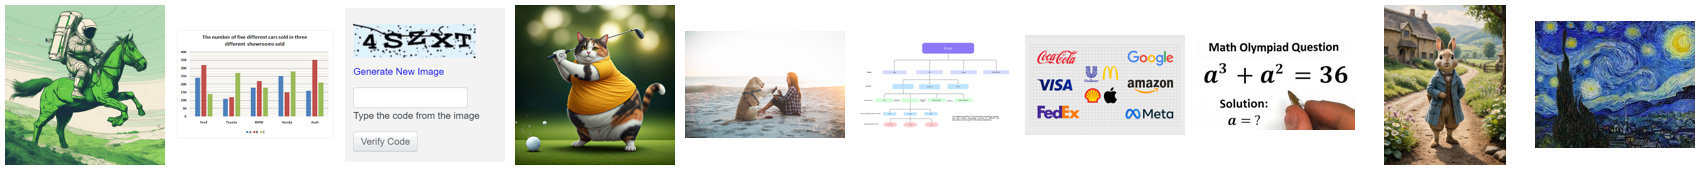

In [5]:
# Thumbnails of the 10 images
thumbs = []
for p in PROMPTS.image:
    im = Image.open(p).convert('RGB')
    im.thumbnail((160, 160))
    thumbs.append(im)
sheet = Image.new('RGB', (170 * len(thumbs), 170), 'white')
for i, im in enumerate(thumbs):
    sheet.paste(im, (170 * i + (170 - im.width) // 2, (170 - im.height) // 2))
display(sheet)

## 5. Generate

Greedy decoding (temperature 0), so results are reproducible. Each image is a separate conversation: the model's chat
template with one image and the prompt.

**Power monitoring.** `macmon` (no sudo needed) runs in the background for the whole notebook, sampling the chip's
power sensors about every 110 ms. Each run's energy is split into the **prefill** window (reading the image and
prompt, up to the first output token) and the **decode** window (generating). If `macmon` isn't installed, the power
metrics are left empty and everything else runs. Readings are Apple's on-chip estimates, not a wall-meter measurement.

In [6]:
import atexit
import json
import shutil
import subprocess
import threading

class PowerMonitor:
    """Runs `macmon pipe` in the background and keeps every sample.

    Each sample is the average over the interval since the previous one, so the energy in any time
    window is the sum of power x (overlap of that interval with the window).
    """
    def __init__(self, interval_ms):
        self.samples = []  # (time.perf_counter(), macmon sample dict)
        self.available = shutil.which('macmon') is not None
        if not self.available:
            print('macmon not found: power and energy metrics will be empty (install: brew install macmon)')
            return
        self.proc = subprocess.Popen(['macmon', 'pipe', '-i', str(interval_ms)],
                                     stdout=subprocess.PIPE, stderr=subprocess.DEVNULL, text=True)
        atexit.register(self.proc.terminate)
        threading.Thread(target=self._read, daemon=True).start()
        t_start = time.perf_counter()
        while len(self.samples) < 2 and time.perf_counter() - t_start < 5:  # macmon takes ~0.7 s to start
            time.sleep(0.05)
        self.available = len(self.samples) >= 2

    def _read(self):
        for line in self.proc.stdout:
            try:
                self.samples.append((time.perf_counter(), json.loads(line)))
            except json.JSONDecodeError:
                pass

    def wait_past(self, t, timeout=2.0):
        """Block until a sample covering time t has arrived."""
        deadline = time.perf_counter() + timeout
        while self.samples[-1][0] < t and time.perf_counter() < deadline:
            time.sleep(0.02)

    def window(self, a, b):
        """Samples overlapping [a, b], as (seconds of overlap, sample)."""
        return [(min(t, b) - max(t_prev, a), s)
                for (t_prev, _), (t, s) in zip(self.samples, self.samples[1:])
                if min(t, b) - max(t_prev, a) > 0]

def soc_power(s):
    return s['all_power'] + s['ram_power']  # CPU + GPU + Neural Engine + memory, in watts

def integrate(win, fn):
    return sum(overlap * fn(s) for overlap, s in win)

POWER_KEYS = ['gpu_util_avg_pct', 'gpu_util_peak_pct', 'gpu_freq_avg_mhz', 'gpu_power_avg_w', 'gpu_power_peak_w',
              'soc_power_avg_w', 'gpu_temp_max_c', 'energy_j', 'energy_net_j',
              'prefill_energy_mj_per_input_token', 'decode_energy_mj_per_output_token', 'power_samples']

def summarize_power(t0, t_first, t_end, n_input, n_output):
    if not POWER.available:
        return dict.fromkeys(POWER_KEYS)
    POWER.wait_past(t_end)
    run = POWER.window(t0, t_end)
    samples = [s for _, s in run]
    dur = t_end - t0
    e_soc = integrate(run, soc_power)
    return {
        'gpu_util_avg_pct': round(100 * integrate(run, lambda s: s['gpu_active_ratio']) / dur, 1),
        'gpu_util_peak_pct': round(100 * max(s['gpu_active_ratio'] for s in samples), 1),
        'gpu_freq_avg_mhz': round(integrate(run, lambda s: s['gpu_freq_mhz']) / dur),
        'gpu_power_avg_w': round(integrate(run, lambda s: s['gpu_power']) / dur, 1),
        'gpu_power_peak_w': round(max(s['gpu_power'] for s in samples), 1),
        'soc_power_avg_w': round(e_soc / dur, 1),
        'gpu_temp_max_c': round(max(s['temp']['gpu_temp_avg'] for s in samples), 1),
        'energy_j': round(e_soc, 2),
        'energy_net_j': round(e_soc - IDLE_SOC_W * dur, 2),
        'prefill_energy_mj_per_input_token': round(1000 * integrate(POWER.window(t0, t_first), soc_power) / n_input, 3),
        'decode_energy_mj_per_output_token': round(1000 * integrate(POWER.window(t_first, t_end), soc_power) / max(n_output, 1), 2),
        'power_samples': len(run),
    }

POWER = PowerMonitor(POWER_SAMPLE_MS)
if POWER.available:
    time.sleep(1.0)  # idle baseline, measured with the model loaded but not running
    a, b = POWER.samples[0][0], POWER.samples[-1][0]
    IDLE_SOC_W = integrate(POWER.window(a, b), soc_power) / (b - a)
    print(f'Power monitor running (macmon, ~{POWER_SAMPLE_MS} ms samples). Idle chip power: {IDLE_SOC_W:.2f} W')

def cpu_clusters():
    """CPU cluster names and core counts from macOS (e.g. M5 Max: 6 'Super' + 12 'Performance' cores)."""
    def sysctl(key):
        return subprocess.run(['sysctl', '-n', key], capture_output=True, text=True).stdout.strip()
    return [(sysctl(f'hw.perflevel{i}.name') or f'level{i}', int(sysctl(f'hw.perflevel{i}.logicalcpu') or 0)) for i in (0, 1)]

CPU_CLUSTERS = cpu_clusters()
HARDWARE = {}   # model name -> hardware_metrics() for its whole run

def hardware_metrics(t0, t1):
    """GPU, CPU, Neural Engine (NPU), memory and whole-chip activity over [t0, t1], from the macmon samples.

    macmon calls the two CPU clusters 'pcpu' (perflevel0) and 'ecpu' (perflevel1); they are reported here
    under the names macOS gives them.
    """
    if not POWER.available:
        return None
    POWER.wait_past(t1)
    win = POWER.window(t0, t1)
    samples = [s for _, s in win]
    dur = t1 - t0
    avg = lambda fn: integrate(win, fn) / dur
    peak = lambda fn: max(fn(s) for s in samples)
    energy = lambda fn: round(integrate(win, fn), 2)
    pct = lambda x: round(100 * x, 1)
    (c0_name, c0_cores), (c1_name, c1_cores) = CPU_CLUSTERS
    c0, c1 = c0_name.lower(), c1_name.lower()
    ane = lambda s: s['ane_power']
    return {
        'gpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['gpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['gpu_active_ratio'])),
            'avg_frequency_mhz': round(avg(lambda s: s['gpu_freq_mhz'])),
            'max_frequency_mhz': round(peak(lambda s: s['gpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['gpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['gpu_power']), 1),
            'energy_joules': energy(lambda s: s['gpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['gpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['gpu_temp_avg']), 1),
        },
        'cpu': {
            'avg_utilization_pct': pct(avg(lambda s: s['cpu_active_ratio'])),
            'peak_utilization_pct': pct(peak(lambda s: s['cpu_active_ratio'])),
            f'{c0}_cores': c0_cores,
            f'{c0}_cores_avg_utilization_pct': pct(avg(lambda s: s['pcpu_active_ratio'])),
            f'{c0}_cores_avg_frequency_mhz': round(avg(lambda s: s['pcpu_freq_mhz'])),
            f'{c1}_cores': c1_cores,
            f'{c1}_cores_avg_utilization_pct': pct(avg(lambda s: s['ecpu_active_ratio'])),
            f'{c1}_cores_avg_frequency_mhz': round(avg(lambda s: s['ecpu_freq_mhz'])),
            'avg_power_watts': round(avg(lambda s: s['cpu_power']), 1),
            'peak_power_watts': round(peak(lambda s: s['cpu_power']), 1),
            'energy_joules': energy(lambda s: s['cpu_power']),
            'avg_temperature_c': round(avg(lambda s: s['temp']['cpu_temp_avg']), 1),
            'max_temperature_c': round(peak(lambda s: s['temp']['cpu_temp_avg']), 1),
        },
        'npu': {
            'name': 'Apple Neural Engine (ANE)',
            'used': peak(ane) > 0.05,
            'avg_power_watts': round(avg(ane), 2),
            'peak_power_watts': round(peak(ane), 2),
            'energy_joules': energy(ane),
            'note': 'MLX runs models on the GPU, so the Neural Engine stays idle (about 0 W) during these runs.',
        },
        'system_memory': {
            'avg_power_watts': round(avg(lambda s: s['ram_power']), 1),
            'energy_joules': energy(lambda s: s['ram_power']),
            'ram_total_gb': round(samples[0]['memory']['ram_total'] / 1e9, 1),
            'avg_ram_used_gb': round(avg(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_ram_used_gb': round(peak(lambda s: s['memory']['ram_usage']) / 1e9, 1),
            'peak_swap_used_gb': round(peak(lambda s: s['memory']['swap_usage']) / 1e9, 2),
            'note': 'RAM used is for the whole Mac, including other apps, not just this model.',
        },
        'whole_chip': {
            'avg_power_watts': round(avg(soc_power), 1),
            'peak_power_watts': round(peak(soc_power), 1),
            'energy_joules': energy(soc_power),
            'idle_power_watts': round(IDLE_SOC_W, 2),
            'note': 'CPU + GPU + Neural Engine + memory.',
        },
        'measured_seconds': round(dur, 2),
        'power_samples': len(win),
    }

Power monitor running (macmon, ~100 ms samples). Idle chip power: 0.28 W


### Per-prompt metrics analysis

Every image is wrapped in `metrics_monitor_start()` / `metrics_monitor_stop()` from `macmon_metrics/metrics_monitor.py`,
which records a macmon time series for that image. Results go to a separate folder,
`metrics_analysis/itt/<family>/<params>/<prompt set>/`:

- `System_Level_Metrics/<prompt id>_system_metrics.csv`: CPU / GPU / NPU utilisation, power and temperature, RAM used
  and total system power, sampled every 100 ms while that image was processed
- `Model_Level_Metrics/<model>_prompt_metrics.csv`: one row per image with input tokens (text + image), output tokens,
  the first token generated and its latency, prompt processing rate, inference rate and inference time, followed by
  the image, prompt and response

Section 9 combines every model's `Model_Level_Metrics` CSV into `metrics_analysis/itt/all_models_prompt_metrics_<prompt set>.csv`.

In [7]:
import macmon_metrics.metrics_monitor as mm
from macmon_metrics.metrics_monitor import metrics_monitor_start, metrics_monitor_stop, setup_output_directory

METRICS_ROOT = Path('metrics_analysis/itt')

def analysis_dirs(name):
    """(System_Level_Metrics, Model_Level_Metrics) folders for one model and prompt set."""
    return setup_output_directory(str(METRICS_ROOT / family_of(name) / PARAM_FOLDER[name] / PROMPT_SET))

# Start the macmon tracker now: it takes about a second to produce its first sample, and starting it here means
# every image's capture has samples from its first moment.
if mm._tracker is None:
    mm._tracker = mm.MacMonTracker(binary_path=mm._resolve_macmon_binary())
    mm._tracker.start()
    time.sleep(1.5)

def generate(model, processor, image, prompt):
    formatted = apply_chat_template(processor, model.config, prompt, num_images=1)
    mx.reset_peak_memory()
    text, t_first, first_token = '', None, None
    t0 = time.perf_counter()
    for r in stream_generate(model, processor, formatted, image=[image], max_tokens=MAX_NEW_TOKENS, temperature=0.0):
        if t_first is None:
            t_first = time.perf_counter()   # first token arrives once the image and prompt have been processed
            first_token = r.text
        text += r.text
    t_end = time.perf_counter()
    return {
        'text': text.strip(),
        'total_s': t_end - t0,
        'ttft_s': t_first - t0,
        'first_token': first_token,
        'input_tokens': r.prompt_tokens,
        'output_tokens': r.generation_tokens,
        'prefill_s': r.prompt_tokens / r.prompt_tps if r.prompt_tps else t_first - t0,
        'decode_tps': r.generation_tps,
        'peak_gb': r.peak_memory,
        'finish_reason': r.finish_reason or 'stop',
        'power': summarize_power(t0, t_first, t_end, r.prompt_tokens, r.generation_tokens),
    }

def warm_up(model, processor):
    """Answer the first image once, untimed, so GPU kernels are compiled before anything is measured."""
    generate(model, processor, PROMPTS.image.iloc[0], PROMPTS.prompt.iloc[0])

def save_prompt_metrics(name, runs, folder):
    """Model_Level_Metrics CSV: one row per image."""
    rows = [{
        'prompt_id': g['id'],
        'model': name,
        'family': family_of(name),
        'size': size_of(name),
        'image_size (px)': g['image_size'],
        'input_tokens': g['input_tokens'],
        'output_tokens': g['output_tokens'],
        'output_words': g['words'],
        'first_token': json.dumps(g['first_token'])[1:-1],   # escaped, so newlines/spaces stay visible in the CSV
        'time_to_first_token (ms)': round(1000 * g['ttft_s'], 1),
        'prompt_processing_rate (tokens/s)': round(g['input_tokens'] / g['prefill_s'], 1),
        'inference_rate (tokens/s)': round(g['decode_tps'], 2),
        'inference_time (s)': round(g['total_s'], 3),
        'image': g['image'],
        'prompt': g['prompt'],
        'response': g['text'],
    } for g in runs]
    path = Path(folder) / f'{name}_prompt_metrics.csv'
    pd.DataFrame(rows).to_csv(path, index=False)
    return path

def run_prompt_set(model, processor, name):
    warm_up(model, processor)
    sys_dir, model_dir = analysis_dirs(name)
    runs = []
    t_start = time.perf_counter()
    for row in PROMPTS.itertuples(index=False):
        metrics_monitor_start(idx=row.id, metrics_folder=sys_dir)
        g = generate(model, processor, row.image, row.prompt)
        metrics_monitor_stop()
        g.update(id=row.id, image=row.image, image_size=row.image_size, prompt=row.prompt, words=len(g['text'].split()))
        runs.append(g)
        print(f"  [{row.id}] {row.image_size:>9} -> {g['input_tokens']:>5} in, {g['output_tokens']:>4} out, "
              f"first token {1000 * g['ttft_s']:6.0f} ms, {g['decode_tps']:5.1f} tok/s, {g['total_s']:5.1f}s ({g['finish_reason']})")
    HARDWARE[name] = hardware_metrics(t_start, time.perf_counter())
    print(f'Per-prompt metrics: {save_prompt_metrics(name, runs, model_dir)} (+ {len(runs)} system CSVs in {sys_dir})')
    return runs

print(f'Running {len(PROMPTS)} images on {model_name}...')
runs = run_prompt_set(model, processor, model_name)
print(f"Done: {sum(g['output_tokens'] for g in runs):,} tokens in {sum(g['total_s'] for g in runs):.1f}s")

Running 10 images on SmolVLM-Instruct...


  [01] 1024x1024 ->  1562 in,  182 out, first token    531 ms, 244.6 tok/s,   1.3s (stop)


  [02]   270x187 ->  1197 in,  368 out, first token    407 ms, 246.7 tok/s,   1.9s (stop)


  [03]   352x339 ->  1562 in,  115 out, first token    522 ms, 245.6 tok/s,   1.0s (stop)


  [04] 2048x2048 ->  1562 in,  207 out, first token    539 ms, 243.8 tok/s,   1.4s (stop)


...

/Users/genailab/mlx-projects/.venv/lib/python3.12/site-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  [07] 2240x1400 ->  1197 in,  150 out, first token    422 ms, 248.5 tok/s,   1.0s (stop)


  [08]   299x168 ->  1197 in,   62 out, first token    397 ms, 257.7 tok/s,   0.6s (stop)


  [09] 2048x2688 ->  1562 in,  348 out, first token    559 ms, 247.1 tok/s,   2.0s (stop)


  [10]   251x200 ->  1562 in,  104 out, first token    519 ms, 246.6 tok/s,   0.9s (stop)
Per-prompt metrics: metrics_analysis/itt/SmolVLM/2.2B/itt_prompts_10/Model_Level_Metrics/SmolVLM-Instruct_prompt_metrics.csv (+ 10 system CSVs in metrics_analysis/itt/SmolVLM/2.2B/itt_prompts_10/System_Level_Metrics)
Done: 2,687 tokens in 15.7s


## 6. Save the responses

One text file per image: `outputs/itt/<family>/<params>/<prompt set>/<model>_response_<id>.txt`.

In [8]:
import textwrap

def save_responses(name, runs):
    d = out_dir(name)
    for g in runs:
        (d / f"{name}_response_{g['id']}.txt").write_text(g['text'] + '\n')
    return d

saved_to = save_responses(model_name, runs)
print(f'Saved {len(runs)} responses to {saved_to}/\n')
for g in runs[:2]:
    print(f"=== Image {g['id']} ({g['image']}): {g['prompt']}")
    print(textwrap.fill(g['text'][:800], width=100, replace_whitespace=False) + (' ...' if len(g['text']) > 800 else ''), end='\n\n')

Saved 10 responses to outputs/itt/SmolVLM/2.2B/itt_prompts_10/

=== Image 01 (prompts/images_itt_prompts/itt_prompts_10/01.png): Describe this image in detail.
The image depicts an astronaut riding a green horse in a surreal landscape. The astronaut is in a
white spacesuit with a helmet and backpack, and is riding a green horse with a long, flowing mane
and tail. The horse is standing on a green field with a hill in the background. The sky is light
green with some darker green clouds. The image is drawn in a cartoon style with thick, bold lines
and vibrant colors. The artist has used a variety of techniques to create a sense of depth and
realism, including shading, perspective, and foreshortening. The image is full of vibrant colors and
textures, which create a sense of movement and energy. The artist has used a variety of techniques
to create a sense of depth and realism, including shading, perspective, and foreshortening. The
image is full of v ...

=== Image 02 (prompts/images_itt_p

## 7. Cost of this run

Per image and in total. Electricity cost = energy per token × `ELECTRICITY_USD_PER_KWH` (1 kWh = 3.6 MJ). The metrics
for each model are saved as `<model>_simple_metrics.json` in its output folder.

In [9]:
def usd_per_1m(mj_per_token):
    """Electricity cost of one million tokens: mJ/token -> kWh (1 kWh = 3.6e9 mJ) -> $."""
    return None if mj_per_token is None else round(mj_per_token * 1e6 / 3.6e9 * ELECTRICITY_USD_PER_KWH, 5)

def weighted(runs, key, weight):
    pairs = [(g['power'][key], g[weight]) for g in runs if g['power'][key] is not None]
    total = sum(w for _, w in pairs)
    return round(sum(v * w for v, w in pairs) / total, 3) if pairs and total else None

def simple_metrics(name, runs, load_s):
    """A flat, readable summary of one model's run: plain names, units in every key."""
    s = SPECS.loc[name]
    n = len(runs)
    tot_in, tot_out = sum(g['input_tokens'] for g in runs), sum(g['output_tokens'] for g in runs)
    gen_s = sum(g['total_s'] for g in runs)
    decode_s = sum(g['output_tokens'] / g['decode_tps'] for g in runs if g['decode_tps'])
    measured = runs[0]['power']['energy_j'] is not None
    energy = sum(g['power']['energy_j'] for g in runs) if measured else None
    words = [g['words'] for g in runs]
    mj_in = weighted(runs, 'prefill_energy_mj_per_input_token', 'input_tokens')
    mj_out = weighted(runs, 'decode_energy_mj_per_output_token', 'output_tokens')
    return {
        'model': name, 'family': family_of(name), 'size': size_of(name), 'repo': MLX_REPOS[name],
        'parameters_billion': round(s.params / 1e9, 2), 'quantization': '4-bit', 'image_handling': s.image_handling,
        'prompt_set': PROMPT_SET, 'prompts_run': n,
        'tokens': {
            'input_total': tot_in, 'output_total': tot_out,
            'input_avg_per_image': round(tot_in / n), 'output_avg_per_image': round(tot_out / n),
            'input_min': min(g['input_tokens'] for g in runs), 'input_max': max(g['input_tokens'] for g in runs),
            'output_limit_per_image': MAX_NEW_TOKENS,
        },
        'response_length': {
            'avg_words': round(sum(words) / n), 'min_words': min(words), 'max_words': max(words),
            'responses_cut_off_at_token_limit': sum(g['finish_reason'] == 'length' for g in runs),
        },
        'speed': {
            'model_load_seconds': round(load_s, 1),
            'total_generation_seconds': round(gen_s, 1),
            'avg_seconds_per_image': round(gen_s / n, 2),
            'avg_time_to_first_token_ms': round(1000 * sum(g['ttft_s'] for g in runs) / n),
            'prompt_processing_tokens_per_second': round(tot_in / sum(g['prefill_s'] for g in runs)),
            'generation_tokens_per_second': round(tot_out / decode_s, 1) if decode_s else None,
        },
        'memory': {'weights_gb': float(s.download_gb), 'peak_memory_gb': round(max(g['peak_gb'] for g in runs), 2)},
        **(HARDWARE.get(name) or {'hardware': 'not measured (macmon not available)'}),
        'energy': {
            'total_joules': round(energy, 1) if measured else None,
            'avg_joules_per_image': round(energy / n, 1) if measured else None,
            'per_input_token_millijoules': mj_in,
            'per_output_token_millijoules': mj_out,
        },
        'cost_usd': {
            'api_fee': 0.0,
            'electricity_whole_run': round(energy / 3.6e6 * ELECTRICITY_USD_PER_KWH, 6) if measured else None,
            'electricity_per_1m_input_tokens': usd_per_1m(mj_in),
            'electricity_per_1m_output_tokens': usd_per_1m(mj_out),
            'electricity_price_per_kwh': ELECTRICITY_USD_PER_KWH,
        },
        'per_image': [{
            'id': g['id'], 'image_size_px': g['image_size'], 'input_tokens': g['input_tokens'],
            'output_tokens': g['output_tokens'], 'words': g['words'], 'seconds': round(g['total_s'], 2),
            'time_to_first_token_ms': round(1000 * g['ttft_s']), 'tokens_per_second': round(g['decode_tps'], 1),
            'energy_joules': g['power']['energy_j'], 'cut_off_at_token_limit': g['finish_reason'] == 'length',
        } for g in runs],
    }

def finish_model(name, runs, load_s):
    save_responses(name, runs)
    sm = simple_metrics(name, runs, load_s)
    (out_dir(name) / f'{name}_simple_metrics.json').write_text(json.dumps(sm, indent=2))
    return sm

sm = finish_model(model_name, runs, load_seconds)
rows = [
    ('Images', f"{sm['prompts_run']} ({sm['response_length']['responses_cut_off_at_token_limit']} hit the {MAX_NEW_TOKENS}-token limit)"),
    ('Input / output tokens (total)', f"{sm['tokens']['input_total']:,} / {sm['tokens']['output_total']:,}"),
    ('Input tokens per image (min - max)', f"{sm['tokens']['input_min']:,} - {sm['tokens']['input_max']:,}"),
    ('Time to first token (avg)', f"{sm['speed']['avg_time_to_first_token_ms']:,} ms"),
    ('Prompt processing / generation speed', f"{sm['speed']['prompt_processing_tokens_per_second']:,} / {sm['speed']['generation_tokens_per_second']} tok/s"),
    ('Total generation time', f"{sm['speed']['total_generation_seconds']} s"),
    ('Average response length', f"{sm['response_length']['avg_words']} words"),
    ('Peak memory', f"{sm['memory']['peak_memory_gb']} GB"),
    ('API cost', '$0.00 (runs locally)'),
]
if sm['energy']['total_joules'] is not None:
    rows += [
        ('GPU busy / power (avg)', f"{sm['gpu']['avg_utilization_pct']}% / {sm['gpu']['avg_power_watts']} W"),
        ('CPU busy / power (avg)', f"{sm['cpu']['avg_utilization_pct']}% / {sm['cpu']['avg_power_watts']} W"),
        ('NPU (Neural Engine) power (avg)', f"{sm['npu']['avg_power_watts']} W"),
        ('Energy for the whole set', f"{sm['energy']['total_joules']} J"),
        ('Energy per input / output token', f"{sm['energy']['per_input_token_millijoules']} / {sm['energy']['per_output_token_millijoules']} mJ"),
    ]
display(pd.DataFrame(rows, columns=['Metric', model_name]).style.hide(axis='index'))
pd.read_csv(Path(METRICS_ROOT / family_of(model_name) / PARAM_FOLDER[model_name] / PROMPT_SET / 'Model_Level_Metrics'
                 / f'{model_name}_prompt_metrics.csv'), dtype={'prompt_id': str}).drop(
    columns=['model', 'family', 'size', 'image', 'prompt', 'response']).style.hide(axis='index')

Metric,SmolVLM-Instruct
Images,10 (0 hit the 1024-token limit)
Input / output tokens (total),"13,795 / 2,687"
Input tokens per image (min - max),"1,197 - 1,562"
Time to first token (avg),474 ms
Prompt processing / generation speed,"3,383 / 246.8 tok/s"
Total generation time,15.7 s
Average response length,201 words
Peak memory,2.53 GB
API cost,$0.00 (runs locally)
GPU busy / power (avg),90.4% / 33.9 W


prompt_id,image_size (px),input_tokens,output_tokens,output_words,first_token,time_to_first_token (ms),prompt_processing_rate (tokens/s),inference_rate (tokens/s),inference_time (s)
01,1024x1024,1562,182,153,nan,530.800000,3375.500000,244.610000,1.279000
02,270x187,1197,368,275,nan,406.700000,3351.800000,246.720000,1.902000
03,352x339,1562,115,100,nan,521.700000,3402.300000,245.630000,0.994000
04,2048x2048,1562,207,171,nan,539.400000,3420.400000,243.830000,1.393000
05,2048x1365,1197,345,288,nan,419.500000,3379.600000,246.630000,1.822000
06,1920x1080,1197,806,496,nan,419.200000,3334.100000,247.270000,3.682000
07,2240x1400,1197,150,90,nan,422.400000,3363.000000,248.540000,1.029000
08,299x168,1197,62,45,nan,397.500000,3391.400000,257.730000,0.642000
09,2048x2688,1562,348,300,nan,559.400000,3402.100000,247.090000,1.971000
10,251x200,1562,104,89,nan,519.400000,3392.800000,246.550000,0.946000


## 8. Compare every size in the family

Runs the images through every other size of `FAMILY` (reusing the results already produced for `SIZE`), unloading each
model before the next. Set `ITT_COMPARE=0` (or `RUN_FAMILY_COMPARISON = False` in section 1) to skip.

In [10]:
import gc

results = {SIZE: (sm, runs)}
if RUN_FAMILY_COMPARISON:
    del model, processor
    gc.collect()
    mx.clear_cache()
    for size, name in MODEL_NAME[PLATFORM][TASK][FAMILY].items():
        if size == SIZE:
            continue
        print(f'{size}: {name}')
        m, proc, load_s = load_vlm(name)
        r = run_prompt_set(m, proc, name)
        del m, proc
        gc.collect()
        mx.clear_cache()
        results[size] = (finish_model(name, r, load_s), r)

order = [s for s in ('SMALL', 'MEDIUM', 'LARGE') if s in results]
compare = pd.DataFrame({
    s: {
        'Model': r_['model'],
        'Params (B)': f"{r_['parameters_billion']:.2f}",
        'Input / output tokens': f"{r_['tokens']['input_total']:,} / {r_['tokens']['output_total']:,}",
        'Avg words': r_['response_length']['avg_words'],
        'Time to first token (ms)': f"{r_['speed']['avg_time_to_first_token_ms']:,}",
        'Prompt processing (tok/s)': f"{r_['speed']['prompt_processing_tokens_per_second']:,}",
        'Generation (tok/s)': r_['speed']['generation_tokens_per_second'],
        'Total time (s)': r_['speed']['total_generation_seconds'],
        'Peak memory (GB)': r_['memory']['peak_memory_gb'],
        'GPU busy (%)': r_.get('gpu', {}).get('avg_utilization_pct'),
        'GPU power (W)': r_.get('gpu', {}).get('avg_power_watts'),
        'Energy (J)': r_['energy']['total_joules'],
    } for s in order for r_ in [results[s][0]]
})
compare.columns.name = FAMILY
compare

SmolVLM,LARGE
Model,SmolVLM-Instruct
Params (B),2.25
Input / output tokens,"13,795 / 2,687"
Avg words,201
Time to first token (ms),474
Prompt processing (tok/s),"3,383"
Generation (tok/s),246.8
Total time (s),15.7
Peak memory (GB),2.53
GPU busy (%),90.4


In [11]:
# The first two images' responses from each size, side by side
for g_idx in (0, 1):
    for s in order:
        g = results[s][1][g_idx]
        print(f"=== Image {g['id']} — {s}: {results[s][0]['model']} ({g['words']} words) ===")
        print(textwrap.fill(g['text'][:500], width=100, replace_whitespace=False) + (' ...' if len(g['text']) > 500 else ''), end='\n\n')

=== Image 01 — LARGE: SmolVLM-Instruct (153 words) ===
The image depicts an astronaut riding a green horse in a surreal landscape. The astronaut is in a
white spacesuit with a helmet and backpack, and is riding a green horse with a long, flowing mane
and tail. The horse is standing on a green field with a hill in the background. The sky is light
green with some darker green clouds. The image is drawn in a cartoon style with thick, bold lines
and vibrant colors. The artist has used a variety of techniques to create a sense of depth and
realism, inclu ...

=== Image 02 — LARGE: SmolVLM-Instruct (275 words) ===
The image is a bar chart titled "The number of five different cars sold three different showrooms
sold." The chart is divided into five categories: Ford, Toyota, BMW, Honda, and Audi. Each category
is represented by three bars, one for each of the three showrooms. The x-axis measures the number of
cars sold, while the y-axis measures the type of car sold.

The chart shows that Ford

## 9. All models on this prompt set

Collects every model run so far (any family and size, from this notebook or terminal runs):
`outputs/itt/all_models_<prompt set>.json` / `.csv` from the simple metrics, and
`metrics_analysis/itt/all_models_prompt_metrics_<prompt set>.csv` from the per-prompt CSVs.

In [12]:
FAMILY_ORDER = list(MODEL_NAME[PLATFORM][TASK])
SIZE_ORDER = ['SMALL', 'MEDIUM', 'LARGE']
files = Path('outputs/itt').glob(f'*/*/{PROMPT_SET}/*_simple_metrics.json')
models = sorted((json.loads(f.read_text()) for f in files),
                key=lambda m: (FAMILY_ORDER.index(m['family']), SIZE_ORDER.index(m['size'])))
overview = [{k: v for k, v in m.items() if k != 'per_image'} for m in models]
all_json = Path('outputs/itt') / f'all_models_{PROMPT_SET}.json'
all_json.write_text(json.dumps({'prompt_set': PROMPT_SET, 'models': overview}, indent=2))
flat = pd.json_normalize(overview)
flat.to_csv(all_json.with_suffix('.csv'), index=False)
print(f'{len(models)} models -> {all_json} and {all_json.with_suffix(".csv")}')

pd.DataFrame({
    'Family': flat['family'], 'Size': flat['size'], 'Model': flat['model'],
    'Params (B)': flat['parameters_billion'],
    'Input tokens': flat['tokens.input_total'],
    'Output tokens': flat['tokens.output_total'],
    'First token (ms)': flat['speed.avg_time_to_first_token_ms'],
    'Gen tok/s': flat['speed.generation_tokens_per_second'],
    'Total time (s)': flat['speed.total_generation_seconds'],
    'Peak memory (GB)': flat['memory.peak_memory_gb'],
    'GPU busy (%)': flat.get('gpu.avg_utilization_pct'),
    'GPU power (W)': flat.get('gpu.avg_power_watts'),
    'CPU busy (%)': flat.get('cpu.avg_utilization_pct'),
    'NPU power (W)': flat.get('npu.avg_power_watts'),
    'Energy (J)': flat['energy.total_joules'],
}).style.hide(axis='index')

11 models -> outputs/itt/all_models_itt_prompts_10.json and outputs/itt/all_models_itt_prompts_10.csv


Family,Size,Model,Params (B),Input tokens,Output tokens,First token (ms),Gen tok/s,Total time (s),Peak memory (GB),GPU busy (%),GPU power (W),CPU busy (%),NPU power (W),Energy (J)
Qwen2-VL,SMALL,Qwen2-VL-2B-Instruct,2.210000,24599,1984,3388,319.000000,40.100000,3.040000,96.000000,35.700000,3.600000,0.000000,1709.600000
Qwen2-VL,LARGE,Qwen2-VL-7B-Instruct,8.290000,24599,2390,4210,106.100000,64.700000,6.460000,98.000000,30.900000,4.000000,0.040000,2581.800000
Qwen2.5-VL,SMALL,Qwen2.5-VL-3B-Instruct,3.750000,24599,4706,1022,191.200000,34.900000,4.810000,96.000000,46.300000,9.300000,0.000000,2181.600000
Qwen2.5-VL,MEDIUM,Qwen2.5-VL-7B-Instruct,8.290000,24599,2494,1629,112.100000,38.600000,7.380000,96.000000,39.700000,10.500000,0.000000,2142.200000
Qwen2.5-VL,LARGE,Qwen2.5-VL-32B-Instruct,33.450000,24599,6293,5087,26.100000,292.000000,22.520000,99.400000,22.800000,4.900000,0.000000,11276.900000
Gemma-3,SMALL,gemma-3-4b-it,4.300000,2760,5600,326,168.300000,36.600000,3.920000,96.300000,34.800000,6.800000,0.000000,1910.400000
Gemma-3,MEDIUM,gemma-3-12b-it,12.190000,2760,4964,490,62.400000,84.500000,8.380000,98.500000,33.400000,6.900000,0.000000,4277.000000
Gemma-3,LARGE,gemma-3-27b-it,27.430000,2760,4417,720,31.000000,149.800000,16.990000,99.200000,37.600000,5.000000,0.000000,8545.300000
SmolVLM,SMALL,SmolVLM-256M-Instruct,0.260000,10085,8632,222,533.100000,18.400000,1.070000,91.500000,14.400000,17.500000,0.000000,549.500000
SmolVLM,MEDIUM,SmolVLM-500M-Instruct,0.510000,10085,8472,238,441.200000,21.600000,1.230000,91.400000,18.900000,15.200000,0.000000,729.000000


In [13]:
# Every model's per-prompt metrics (Model_Level_Metrics) in one CSV
prompt_csvs = sorted(Path('metrics_analysis/itt').glob(f'*/*/{PROMPT_SET}/Model_Level_Metrics/*_prompt_metrics.csv'))
all_prompts = pd.concat([pd.read_csv(p, dtype={'prompt_id': str}) for p in prompt_csvs], ignore_index=True)
all_prompts['family'] = pd.Categorical(all_prompts['family'], FAMILY_ORDER, ordered=True)
all_prompts['size'] = pd.Categorical(all_prompts['size'], SIZE_ORDER, ordered=True)
all_prompts = all_prompts.sort_values(['family', 'size', 'prompt_id'])
combined_csv = Path('metrics_analysis/itt') / f'all_models_prompt_metrics_{PROMPT_SET}.csv'
all_prompts.to_csv(combined_csv, index=False)
print(f'{len(prompt_csvs)} models, {len(all_prompts)} prompt rows -> {combined_csv}')
all_prompts.groupby(['family', 'size', 'model'], observed=True).agg(
    images=('prompt_id', 'count'), input_tokens=('input_tokens', 'sum'), output_tokens=('output_tokens', 'sum'),
    avg_ttft_ms=('time_to_first_token (ms)', 'mean'), avg_inference_rate=('inference_rate (tokens/s)', 'mean'),
    total_inference_time_s=('inference_time (s)', 'sum')).round(1)

11 models, 110 prompt rows -> metrics_analysis/itt/all_models_prompt_metrics_itt_prompts_10.csv


images  input_tokens  \
family     size   model                                           
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct         10         24599   
           LARGE  Qwen2-VL-7B-Instruct         10         24599   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct       10         24599   
           MEDIUM Qwen2.5-VL-7B-Instruct       10         24599   
           LARGE  Qwen2.5-VL-32B-Instruct      10         24599   
Gemma-3    SMALL  gemma-3-4b-it                10          2760   
           MEDIUM gemma-3-12b-it               10          2760   
           LARGE  gemma-3-27b-it               10          2760   
SmolVLM    SMALL  SmolVLM-256M-Instruct        10         10085   
           MEDIUM SmolVLM-500M-Instruct        10         10085   
           LARGE  SmolVLM-Instruct             10         13795   

                                           output_tokens  avg_ttft_ms  \
family     size   model                                                 
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct              1984       3387.8   
           LARGE  Qwen2-VL-7B-Instruct              2390       4209.6   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct            4706       1021.8   
           MEDIUM Qwen2.5-VL-7B-Instruct            2494       1628.5   
           LARGE  Qwen2.5-VL-32B-Instruct           6293       5087.2   
Gemma-3    SMALL  gemma-3-4b-it                     5600        326.1   
           MEDIUM gemma-3-12b-it                    4964        489.6   
           LARGE  gemma-3-27b-it                    4417        719.8   
SmolVLM    SMALL  SmolVLM-256M-Instruct             8632        222.1   
           MEDIUM SmolVLM-500M-Instruct             8472        238.5   
           LARGE  SmolVLM-Instruct                  2687        473.6   

                                           avg_inference_rate  \
family     size   model                                         
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct                  316.0   
           LARGE  Qwen2-VL-7B-Instruct                  106.5   
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct                200.9   
           MEDIUM Qwen2.5-VL-7B-Instruct                112.4   
           LARGE  Qwen2.5-VL-32B-Instruct                26.2   
Gemma-3    SMALL  gemma-3-4b-it                         168.7   
           MEDIUM gemma-3-12b-it                         62.5   
           LARGE  gemma-3-27b-it                         31.0   
SmolVLM    SMALL  SmolVLM-256M-Instruct                 539.5   
           MEDIUM SmolVLM-500M-Instruct                 441.6   
           LARGE  SmolVLM-Instruct                      247.5   

                                           total_inference_time_s  
family     size   model                                            
Qwen2-VL   SMALL  Qwen2-VL-2B-Instruct                       40.1  
           LARGE  Qwen2-VL-7B-Instruct                       64.7  
Qwen2.5-VL SMALL  Qwen2.5-VL-3B-Instruct                     34.9  
           MEDIUM Qwen2.5-VL-7B-Instruct                     38.6  
           LARGE  Qwen2.5-VL-32B-Instruct                   292.0  
Gemma-3    SMALL  gemma-3-4b-it                              36.6  
           MEDIUM gemma-3-12b-it                             84.5  
           LARGE  gemma-3-27b-it                            149.8  
SmolVLM    SMALL  SmolVLM-256M-Instruct                      18.4  
           MEDIUM SmolVLM-500M-Instruct                      21.6  
           LARGE  SmolVLM-Instruct                           15.7